# Predicting age from DNA methylation

----

### Imports

In [50]:
import os
import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn
import gzip
from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso, LassoCV
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import KFold, GridSearchCV, cross_val_predict
from sklearn.metrics import mean_squared_error, mean_absolute_error

import time

from sklearn.ensemble import BaggingRegressor

In [51]:
print("python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scipy", scipy.__version__, "| scikit-learn", sklearn.__version__)

python 3.11.16 | numpy 2.4.6 | pandas 2.3.3 | scipy 1.16.3 | scikit-learn 1.9.1


### Setup

In [52]:
SEED = 42
np.random.seed(SEED)

# Folders
DATA_DIR = Path(os.environ.get("DATA_DIR", "data"))
RAW_DIR = DATA_DIR / "raw"
PROC_DIR = DATA_DIR / "processed"
FIG_DIR = Path("figures")
for d in (RAW_DIR, PROC_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

# Settings
N_CPGS = int(os.environ.get("N_CPGS", 20_000))          # CpG sites to keep (highest variance, no age information used)
CHUNK_ROWS = int(os.environ.get("CHUNK_ROWS", 25_000))  # rows read at a time (keeps memory low)
TEST_SIZE = 0.2

sns.set_theme(style="whitegrid", context="notebook")

### 1. Data

The data is downloaded from GEO (GSE40279). The methylation file is large (about 1.1 GB), so it is downloaded only once and reused afterwards. It does not contain the ages. The ages are in the sample information at the top of another GEO file, the *series matrix* file, and I read only the first part of that file.

In [53]:
BASE_URL = os.environ.get("GEO_BASE_URL", "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE40nnn/GSE40279/")
BETA_FILE = "GSE40279_average_beta.txt.gz"     # methylation values (beta, 0 to 1): rows = CpG sites, columns = samples
MATRIX_FILE = "GSE40279_series_matrix.txt.gz"  # its first lines hold the sample information (title with age)


def download(name, folder):
    dest = RAW_DIR / name
    if dest.exists():
        print("already downloaded:", dest)
    else:
        print("downloading", name, "(this can take a while for the large file) ...")
        urllib.request.urlretrieve(BASE_URL + folder + name, dest)
    return dest


beta_path = download(BETA_FILE, "suppl/")

already downloaded: data/raw/GSE40279_average_beta.txt.gz


**How the methylation file looks**
- Each row is one CpG site, a specific spot on the DNA where a methylation mark can sit. There are about 450,000 rows.
- Each column is one blood sample, meaning one person. There are 656 columns.
- Each cell is the beta value: the fraction of DNA copies at that site that are methylated in that person's blood. It goes from 0 (none) to 1 (all).

### 1.1 Sample information and age

On GEO, each sample has a title such as `age 67y 1001`: the age in years and a sample number. The methylation file names its columns after the sample number (`X1001`, `X1002`, ...). The cells below read the sample titles and link the two.

In [54]:
info_path = RAW_DIR / "GSE40279_sample_info.csv"


def read_matrix_header(source):
    # Sample information lines start with '!Sample_'. Stop before the big data table.
    rows = {}
    with gzip.open(source, "rt", encoding="utf-8", errors="replace") as f:
        for line in f:
            if line.startswith("!series_matrix_table_begin"):
                break
            if line.startswith("!Sample_"):
                parts = line.rstrip("\n").split("\t") # splits each line on tabs
                rows.setdefault(parts[0], []).append([p.strip().strip('"') for p in parts[1:]]) # stores the values in a dictionary under the field name
    return rows


if info_path.exists(): # if GSE40279_sample_info.csv already exists, it just loads it
    print("already downloaded:", info_path)
    info = pd.read_csv(info_path, dtype=str)
else:
    local_copy = RAW_DIR / MATRIX_FILE
    if local_copy.exists():                        # a copy downloaded by hand
        header = read_matrix_header(local_copy)
    else:                                          # stream only the beginning from GEO
        req = urllib.request.Request(BASE_URL + "matrix/" + MATRIX_FILE, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req) as resp:
            header = read_matrix_header(resp)
    info = pd.DataFrame({
        "gsm": header["!Sample_geo_accession"][0],
        "title": header["!Sample_title"][0],
    })
    # other sample characteristics come as one line each, like 'age (y): 67'
    for line in header.get("!Sample_characteristics_ch1", []):
        name = line[0].split(":")[0].strip()
        info[name] = [c.split(":", 1)[1].strip() if ":" in c else c for c in line]
    info.to_csv(info_path, index=False)
    print("saved:", info_path)

print("sample information:", info.shape)
display(info.head())

already downloaded: data/raw/GSE40279_sample_info.csv
sample information: (656, 8)


,gsm,title,age (y),source,plate,gender,ethnicity,tissue
0,GSM989827,age 67y 1001,67,UCSD,1,F,Caucasian - European,whole blood
1,GSM989828,age 89y 1002,89,UCSD,1,F,Caucasian - European,whole blood
2,GSM989829,age 66y 1003,66,UCSD,1,F,Caucasian - European,whole blood
3,GSM989830,age 64y 1004,64,UCSD,1,F,Caucasian - European,whole blood
4,GSM989831,age 62y 1005,62,UCSD,1,F,Caucasian - European,whole blood


The `info` table gets one row per sample. It has 656 rows, as many patients exist in the methylation file as well.

In [55]:
# This cell takes the age and sample number out of each title, checks them, and links them to the columns of the methylation file

# Age and sample number from the title, e.g. 'age 67y 1001' -> age 67, sample 1001
parsed = info["title"].str.extract(r"age\s+(?P<age>\d+(?:\.\d+)?)\s*y\s+(?P<sample_id>\d+)")
assert parsed.notna().all().all(), "Some titles do not look like 'age 67y 1001'. Look at info['title']."
ages = pd.to_numeric(parsed["age"])
ages.index = parsed["sample_id"]
ages = ages[~ages.index.duplicated()].rename("age") # list indexed by sample numbers


# Make the sample names comparable. The methylation file calls the samples X1001, while the titles give 1001. clean_id removes the X
def clean_id(s):
    s = str(s).strip()
    s = re.sub(r"^X(?=\d)", "", s)
    return re.sub(r"\.0$", "", s)


# Sample names in the methylation file (first column is the CpG id)
beta_header = pd.read_csv(beta_path, sep="\t", nrows=0).columns.tolist()
sample_names = [clean_id(c) for c in beta_header[1:]]
print("first column names in the file:", beta_header[:4], "->", sample_names[:3])
matched = sum(s in ages.index for s in sample_names)
print(f"samples in methylation file: {len(sample_names)} | with an age: {matched}")
assert matched > 0, "No sample number from the titles matches the column names of the methylation file."
print("age range:", ages.min(), "to", ages.max())

first column names in the file: ['ID_REF', 'X1001', 'X1002', 'X1003'] -> ['1001', '1002', '1003']
samples in methylation file: 656 | with an age: 656
age range: 19 to 101


### 1.2 Reduce the CpG sites

The methylation file has more than 450,000 CpG sites. Reading it all at once would need a lot of memory, so the file is read in chunks and only the 20,000 sites with the highest variance across samples are kept. This choice does not use age, so no information about age leaks into the models. Sites with missing values are dropped. The reduced table is saved so this step runs only once.

In [56]:
subset_path = PROC_DIR / f"gse40279_top{N_CPGS}_variance.csv.gz"

if subset_path.exists():
    print("reduced table already exists:", subset_path)
else:
    best = None
    n_seen = n_missing = 0
    for chunk in pd.read_csv(beta_path, sep="\t", index_col=0, chunksize=CHUNK_ROWS):
        n_seen += len(chunk)
        complete = chunk.dropna()
        n_missing += len(chunk) - len(complete)
        complete = complete.astype(np.float32)
        pool = complete if best is None else pd.concat([best, complete])
        keep = pool.var(axis=1).nlargest(N_CPGS).index
        best = pool.loc[keep]
    print(f"CpG sites read: {n_seen:,} | dropped for missing values: {n_missing:,} | kept: {len(best):,}")
    best.T.to_csv(subset_path)          # samples as rows, CpG sites as columns
    print("saved:", subset_path)

reduced table already exists: data/processed/gse40279_top20000_variance.csv.gz


As said above, this choice does not use age information. But the variance is calculated across all 656 samples, including the ones that will later go into the test set, so the test samples’ methylation values influence which sites are kept. However, this is a mild leak, because it is unsupervised and never touches age.

In [57]:
X_all = pd.read_csv(subset_path, index_col=0) # reads the 20.000-site table (each row is a sample - a person - and each column is a CpG site) -> the sample names are the row indices
X_all.index = X_all.index.map(clean_id) # turns the sample names into the same format as the ages index (removes the X in front of numbers)

common = X_all.index.intersection(ages.index) # lists the samples present in both the methylation table and the age list.
print(f"samples with both methylation and age: {len(common)} of {len(X_all)}") 

X = X_all.loc[common] # methylation rows for the samples -> the table of methylation values the model learns from
y = ages.loc[common] # their ages in the same order -> the age each row should predict
print("X:", X.shape, "| y:", y.shape)

samples with both methylation and age: 656 of 656
X: (656, 20000) | y: (656,)


In [58]:
X

,cg15794987,cg24007926,cg11784298,cg13749548,cg03449867,cg05248234,cg21211688,cg14112997,cg02368820,cg21015022,...,cg07151747,cg11737941,cg11302401,cg08318510,cg20018782,cg01361021,cg23505823,cg02534744,cg01866359,cg15836199
1001,0.088889,0.078671,0.685278,0.840229,0.809179,0.089139,0.866661,0.027789,0.894392,0.815821,...,0.501471,0.307768,0.444242,0.385498,0.485096,0.334181,0.936529,0.366738,0.661993,0.945759
1002,0.017939,0.068703,0.040588,0.890519,0.777497,0.786345,0.001802,0.920189,0.808373,0.804759,...,0.416015,0.456791,0.302708,0.332360,0.353696,0.398225,0.803176,0.272162,0.625127,0.864975
1003,0.857785,0.879688,0.915625,0.137737,0.938865,0.082378,0.917752,0.673476,0.090705,0.066034,...,0.444775,0.313751,0.490705,0.314262,0.471757,0.409232,0.897839,0.222186,0.586895,0.883436
1004,0.874216,0.875867,0.842947,0.891576,0.751748,0.827052,0.052523,0.055367,0.797849,0.792929,...,0.421438,0.424149,0.410801,0.317654,0.456943,0.420321,0.784028,0.342654,0.664091,0.946585
1005,0.041472,0.073924,0.291075,0.000000,0.107903,0.125722,0.867356,0.688170,0.885694,0.865292,...,0.535802,0.370180,0.439179,0.281411,0.405613,0.399884,0.888498,0.318438,0.630109,0.869747
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11092,0.120616,0.142274,0.882968,0.875676,0.000000,0.090914,0.922040,0.673180,0.848430,0.912457,...,0.462723,0.424015,0.446004,0.251400,0.457843,0.369838,0.882430,0.369605,0.649194,0.872407
11093,0.100931,0.863977,0.762626,0.888129,0.782006,0.075093,0.867004,0.734327,0.035149,0.930082,...,0.626218,0.402785,0.488298,0.294856,0.342754,0.297758,0.816158,0.358676,0.787489,0.788016
11094,0.098150,0.120920,0.923828,0.062483,0.853670,0.040534,0.053940,0.704803,0.846289,0.817559,...,0.498972,0.492862,0.436820,0.204903,0.417640,0.302029,0.844086,0.264071,0.632168,0.932433
11095,0.899875,0.067581,0.267483,0.915593,0.000000,0.821528,0.034253,0.717974,0.817440,0.000000,...,0.490087,0.292617,0.445465,0.464969,0.382167,0.302286,0.611559,0.411905,0.663986,0.947870


In [59]:
y

1001     67
1002     89
1003     66
1004     64
1005     62
         ..
11092    78
11093    71
11094    68
11095    61
11096    73
Name: age, Length: 656, dtype: int64

### 1.3 Train/test split

The test set is set aside now and is not touched until the final comparison. All exploration below uses the training set only. The split is stratified by age group so that both sets cover the full age range.

In [60]:
age_group = pd.qcut(y, 5, labels=False, duplicates="drop") # sort samples by age and cuts them into 5 groups of equal size, labelled 0 to 4, from youngest to oldest
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=SEED, stratify=age_group
)

# Save which samples went where, so the split can be reproduced and checked
pd.concat([
    pd.Series("train", index=X_train.index), pd.Series("test", index=X_test.index) # 80/20 split, stratify=age_group splits each age group 80/20 separately (Without it, a random split 
                                                                                   # could leave the test set short of very old or very young people, and the test error would be misleading)
]).rename("set").to_csv(PROC_DIR / "split.csv") # a list of which sample went into which set, so the split can be checked or reproduced later

print(f"training: {X_train.shape[0]} samples | test: {X_test.shape[0]} samples | features: {X_train.shape[1]:,}")
print(f"features per training sample: {X_train.shape[1] / X_train.shape[0]:.0f}")

training: 524 samples | test: 132 samples | features: 20,000
features per training sample: 38


### 2. Exploration - training set only

**a. Age distribution**
<br>

A histogram shows how a single continuous variable is spread out, which matters because a model trained mostly on one age range predicts that range best.

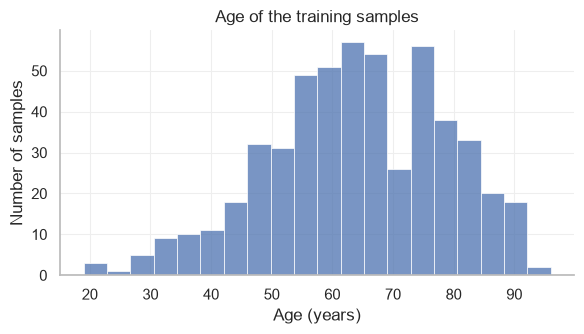

count    524.0
mean      64.0
std       14.7
min       19.0
25%       54.0
50%       65.0
75%       75.0
max       96.0
Name: age, dtype: float64


In [81]:
fig, ax = plt.subplots(figsize=(6, 3.5))
sns.histplot(y_train, bins=20, ax=ax, color="#4C72B0", edgecolor="white", linewidth=0.5)
ax.set_xlabel("Age (years)")
ax.set_ylabel("Number of samples")
ax.set_title("Age of the training samples")

ax.grid(True, color="#eeeeee", linewidth=0.8)   # fainter grid
ax.set_axisbelow(True)                          # grid behind the bars
sns.despine(ax=ax)
ax.spines["left"].set_color("#bbbbbb")
ax.spines["bottom"].set_color("#bbbbbb")

fig.tight_layout()
fig.savefig(FIG_DIR / "age_distribution.png", dpi=200)
plt.show()

print(y_train.describe().round(1))

If a model just guessed 64 (mean age) for everyone, it would be off by about 15 years on average, which is the standard deviation. Any useful model should do better, so this is the "no information" baseline for the rest of the notebook.

**b. Methylation values** 
<br>

Each value (beta) is the fraction of methylated DNA at a site, between 0 and 1. A histogram of the average value per site shows whether sites are mostly unmethylated, mostly methylated or in between and whether the data looks as expected.

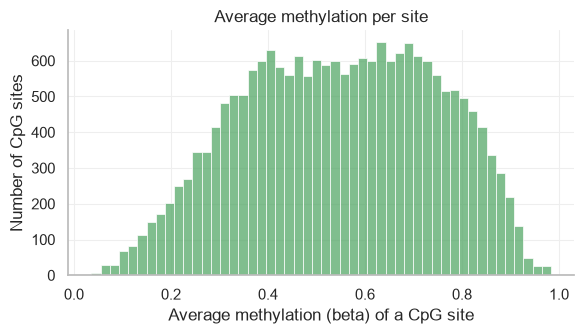

In [82]:
fig, ax = plt.subplots(figsize=(6, 3.5))
sns.histplot(X_train.mean(axis=0), bins=50, ax=ax, color="#55A868", edgecolor="white", linewidth=0.5)
ax.set_xlabel("Average methylation (beta) of a CpG site")
ax.set_ylabel("Number of CpG sites")
ax.set_title("Average methylation per site")

ax.grid(True, color="#eeeeee", linewidth=0.8)   # faint grid
ax.set_axisbelow(True)                          # grid behind the bars
sns.despine(ax=ax)
ax.spines["left"].set_color("#bbbbbb")
ax.spines["bottom"].set_color("#bbbbbb")

fig.tight_layout()
fig.savefig(FIG_DIR / "methylation_distribution.png", dpi=200)
plt.show()

The code calculates the average methylation of each CpG site over the training samples (one number per site, 20,000 in total) and draws a histogram of these numbers with 50 bars. The height of a bar is the number of sites whose average is in that range.

On a methylation array most sites are almost fully unmethylated or almost fully methylated, so the averages usually pile up near 0 and near 1. Here these two piles are missing because of the variance filter that we used earlier. A site that is stuck near 0 or 1 in everyone has low variance, so it was dropped. What is left are sites in the middle, where methylation can differ between people.

A histogram is the right graph because it shows how one continuous number (the average of a site) is spread over many sites and it helps checking that the filter kept sites that are not stuck at 0 or 1.

**c. Methylation against age for a few sites** 
<br>

A scatter plot shows each sample as a point, so the shape of the relationship (roughly a line or not) and the spread around it are visible. These six sites have the strongest correlation with age in the training set. This is only for looking at the data. These sites are not used to choose the features for the models, the models see all sites.

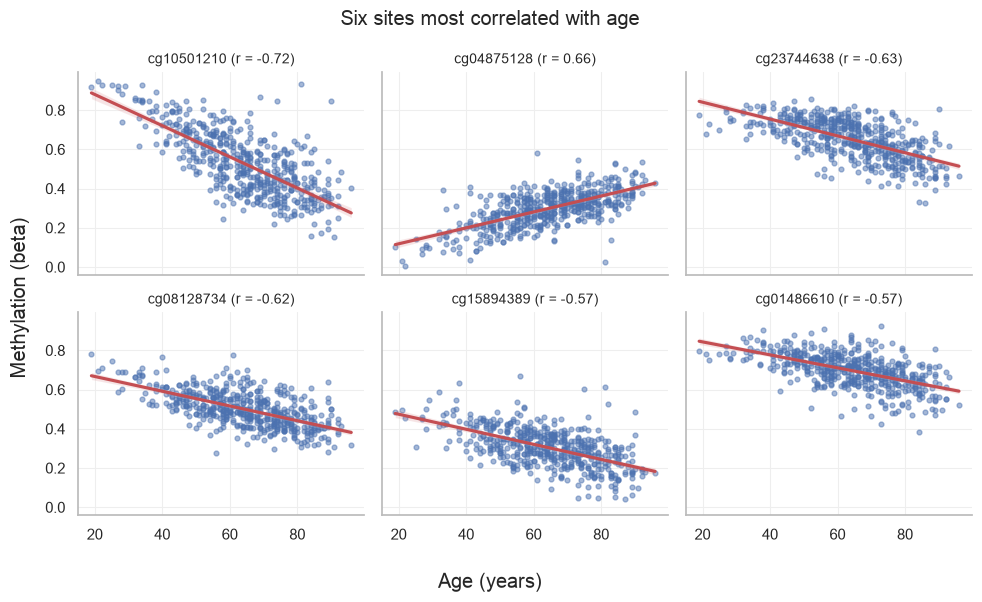

In [84]:
corr = X_train.corrwith(y_train)
top6 = corr.abs().nlargest(6).index

fig, axes = plt.subplots(2, 3, figsize=(10, 6), sharex=True, sharey=True)
for ax, cpg in zip(axes.ravel(), top6):
    sns.regplot(x=y_train, y=X_train[cpg], ax=ax, scatter_kws={"s": 12, "alpha": 0.5},
                line_kws={"color": "#C44E52"})
    ax.set_title(f"{cpg} (r = {corr[cpg]:.2f})", fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")

    ax.grid(True, color="#eeeeee", linewidth=0.8)   # faint grid
    ax.set_axisbelow(True)
    sns.despine(ax=ax)
    ax.spines["left"].set_color("#bbbbbb")
    ax.spines["bottom"].set_color("#bbbbbb")

fig.suptitle("Six sites most correlated with age")
fig.supxlabel("Age (years)")
fig.supylabel("Methylation (beta)")
fig.tight_layout()
fig.savefig(FIG_DIR / "top_cpgs_vs_age.png", dpi=200)
plt.show()

The six sites have correlations between 0.57 and 0.72 in size. Five fall with age (methylation goes down as people get older) and one, cg04875128, goes up with age. This is the kind of age signal the models can use. 

I used scatter plots with a fitted line because both variables are continuous, the points show every person and the spread around the trend and the line shows its direction and strength.

---
### 3. Ridge and lasso

Both methods fit a linear model for age, but they shrink the coefficients. This is what makes it possible to fit a model when there are many more sites than samples. The penalty strength (called alpha) decides how strong the shrinkage is. Ridge shrinks all coefficients towards zero. Lasso shrinks some of them to exactly zero, so it also selects a small set of sites.

To see how well each model works I use **5-fold cross-validation** on the training set. the training samples are split into 5 parts, the model is fitted on 4 parts and tested on the part left out and this is repeated 5 times, so every part is left out once. Both methods use the same folds, and the error is in years. The test set is not used in this section.

The sites are first standardised (mean 0, standard deviation 1), because the penalty treats all coefficients the same, so it depends on the scale of each site. The scaling is learned from the training set only.

In [64]:
RES_DIR = Path("results")
RES_DIR.mkdir(exist_ok=True)

scaler = StandardScaler().fit(X_train)       # scaling learned from the training set only
Z_train = scaler.transform(X_train)          # standardised training data
Z_test = scaler.transform(X_test)            # same scaling, kept for the final comparison (not used yet)

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)   # the same 5 folds for every model


def errors(y_true, y_pred):
    return {
        "RMSE (years)": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAE (years)": float(mean_absolute_error(y_true, y_pred)),
    }

### 3.1 Choose the penalty by cross-validation

For each method I try a range of penalty strengths and keep the one with the lowest cross-validated error. If the best value is at the edge of the range, the range is too narrow and a warning is printed. (In scikit-learn, alpha is the tuning parameter, the penalty strength, which is what is usually called lambda, $λ$)

In [65]:
# Ridge: try a range of penalty strengths and keep the one with the lowest cross-validated error
ridge_alphas = np.logspace(-1, 7, 33)
ridge_search = GridSearchCV(
    Ridge(), {"alpha": ridge_alphas}, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1
)
ridge_search.fit(Z_train, y_train)
ridge_alpha = float(ridge_search.best_params_["alpha"])
print(f"ridge: best alpha = {ridge_alpha:.3g}")
if ridge_alpha in (ridge_alphas[0], ridge_alphas[-1]):
    print("WARNING: the best alpha is at the edge of the range. Widen ridge_alphas and run again.")

ridge: best alpha = 0.1


In [66]:
# Lasso: LassoCV tries many penalty strengths, from strong to weak and keeps the best one.
# alpha_max is the smallest penalty for which lasso keeps no site at all. The path goes from there down by a factor 1000.

alpha_max = np.abs(Z_train.T @ (y_train.values - y_train.mean())).max() / len(y_train)
lasso_alphas = alpha_max * np.logspace(0, -3, 60)
lasso_search = LassoCV(alphas=lasso_alphas, cv=cv, max_iter=5000, n_jobs=-1, random_state=SEED)
lasso_search.fit(Z_train, y_train)
lasso_alpha = float(lasso_search.alpha_)
n_kept = int((lasso_search.coef_ != 0).sum())
print(f"lasso: best alpha = {lasso_alpha:.4f} | sites kept: {n_kept:,} of {Z_train.shape[1]:,}")
if lasso_alpha in (lasso_search.alphas_[0], lasso_search.alphas_[-1]):
    print("WARNING: the best alpha is at the edge of the path. Widen lasso_alphas and run again.")

lasso: best alpha = 0.5679 | sites kept: 151 of 20,000


### 3.2 How well do they work? (cross-validated error)

Each training sample is predicted by a model that was fitted without it (out-of-fold prediction), using the chosen penalty. I add a reference that always predicts the mean age and a useful model has to do better than that.

The penalty was chosen with these same folds, so the numbers are slightly optimistic. The honest estimate is the test set, which is used once at the end.

In [67]:
models = {
    "Reference: always predict the mean age": DummyRegressor(strategy="mean"),
    "Ridge": Ridge(alpha=ridge_alpha),
    "Lasso": Lasso(alpha=lasso_alpha, max_iter=5000),
}
cv_pred, rows = {}, {}
for name, model in models.items():
    cv_pred[name] = cross_val_predict(model, Z_train, y_train, cv=cv, n_jobs=-1)
    rows[name] = errors(y_train, cv_pred[name])

cv_table = pd.DataFrame(rows).T.round(2)
cv_table["sites in the model"] = ["-", f"{Z_train.shape[1]:,}", f"{n_kept:,}"]
cv_table.to_csv(RES_DIR / "cv_errors.csv")
display(cv_table)

,RMSE (years),MAE (years),sites in the model
Reference: always predict the mean age,14.73,11.95,-
Ridge,7.93,6.02,"20,000"
Lasso,6.71,5.22,151


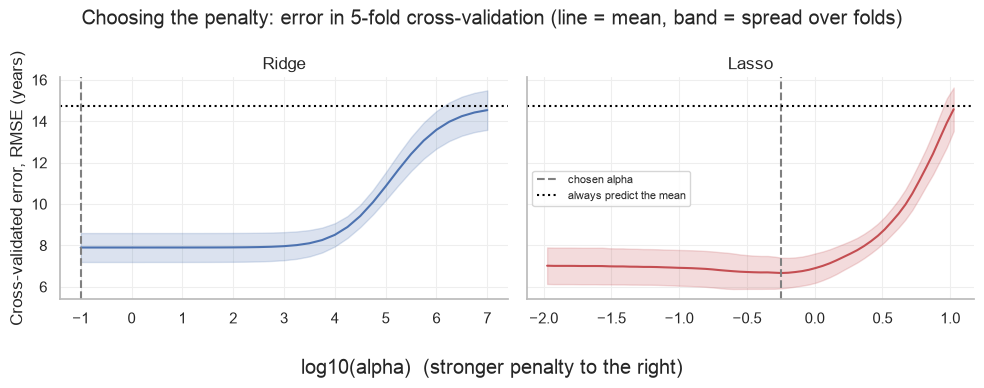

In [85]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
ref_rmse = cv_table.loc["Reference: always predict the mean age", "RMSE (years)"]

# Ridge
res = pd.DataFrame(ridge_search.cv_results_)
x = np.log10(res["param_alpha"].astype(float))
m, s = -res["mean_test_score"], res["std_test_score"]
axes[0].plot(x, m, color="#4C72B0")
axes[0].fill_between(x, m - s, m + s, color="#4C72B0", alpha=0.2)
axes[0].axvline(np.log10(ridge_alpha), ls="--", color="grey", label="chosen alpha")
axes[0].set_title("Ridge")

# Lasso
rmse_path = np.sqrt(lasso_search.mse_path_)          # rows: penalty strengths, columns: folds
x = np.log10(lasso_search.alphas_)
m, s = rmse_path.mean(axis=1), rmse_path.std(axis=1)
axes[1].plot(x, m, color="#C44E52")
axes[1].fill_between(x, m - s, m + s, color="#C44E52", alpha=0.2)
axes[1].axvline(np.log10(lasso_alpha), ls="--", color="grey", label="chosen alpha")
axes[1].set_title("Lasso")

for ax in axes:
    ax.axhline(ref_rmse, ls=":", color="black", label="always predict the mean")
    ax.grid(True, color="#eeeeee", linewidth=0.8)
    ax.set_axisbelow(True)
    sns.despine(ax=ax)
    ax.spines["left"].set_color("#bbbbbb")
    ax.spines["bottom"].set_color("#bbbbbb")
axes[0].set_ylabel("Cross-validated error, RMSE (years)")
axes[1].legend(loc="center left", fontsize=8)
fig.supxlabel("log10(alpha)  (stronger penalty to the right)")
fig.suptitle("Choosing the penalty: error in 5-fold cross-validation (line = mean, band = spread over folds)")
fig.tight_layout()
fig.savefig(FIG_DIR / "cv_curves.png", dpi=200)
plt.show()

**Results.** Both models do much better than the reference, which is off by 14.73 years. Ridge gets 7.93 years and lasso 6.71 years and lasso uses only 151 of the 20,000 sites.

- For ridge the best alpha is at the edge of the range (0.1), but the curve is flat there (any alpha from 0.1 up to about 1000 gives the same error, so the warning does not matter).
- For lasso the lowest point is inside the range, so the range is fine.
- With a very strong penalty both curves go up to the reference line because the model then predicts the mean for everyone.
- These are cross-validated errors. The final comparison is on the test set in section 5.

---
### 4. Bayesian lasso

The Bayesian lasso (Park and Casella 2008) is the lasso written as a Bayesian model. Instead of one best set of coefficients, it gives a whole distribution for every coefficient, so it also gives the uncertainty.

- Each coefficient gets a prior that is peaked at zero (a Laplace prior). This is what gives the lasso-like shrinkage.
- The distribution is found with **Gibbs sampling**. The unknowns are updated one group at a time, each from its distribution given the current values of all the others. The first iterations (burn-in) are thrown away, and the rest are samples from the distribution.
- I run the sampler twice from different starting points (two chains). If both chains end up in the same place, it means that the sampler has converged.
- The penalty strength (lambda) also has to be chosen and I tried two versions:
  - **4A.** Lambda gets its own prior and is learned from the data (Park and Casella, section 3.2). The prior is weak, i.e. a gamma distribution with shape 1 and rate 0.1.
  - **4B.** Lambda is fixed to the value that matches the lasso from cross-validation. This approach is not from the paper.

The sites are standardised and age is centred, as for ridge and lasso. The test set is not used in this section.

In [86]:
N_CHAINS = 2
THIN = 5                                  # save the coefficients of every 5th iteration
R_PRIOR, DELTA_PRIOR = 1.0, 0.1           # the gamma prior on lambda squared (shape, rate), used in 4A

# three sites to follow in the trace plots: the ones with the largest lasso coefficients
n_monitor = 3
monitor_idx = np.argsort(-np.abs(lasso_search.coef_))[:n_monitor]
lasso_sites = lasso_search.coef_ != 0     # the sites the lasso kept


def blasso(Z, y, n_iter, burn_in, seed, lam_start, sigma_start, learn_lambda):
    # Gibbs sampler for the Bayesian lasso (Park and Casella 2008).
    # learn_lambda=True: lambda has its own prior and is updated (4A). False: lambda stays fixed (4B).
    rng = np.random.default_rng(seed)
    n, p = Z.shape
    yc = y - y.mean()                              # age centred, so the intercept is the mean age

    # starting values (different for every chain)
    lam2 = lam_start ** 2                          # lambda squared
    tau2 = rng.exponential(2 / lam2, p)            # one scale for every site
    sigma2 = sigma_start ** 2                      # variance of the noise

    beta_saved = np.empty((len(range(burn_in, n_iter, THIN)), p), dtype=np.float32)
    trace = {"sigma2": np.empty(n_iter), "beta": np.empty((n_iter, n_monitor))}
    if learn_lambda:
        trace["lam2"] = np.empty(n_iter)
    t0 = time.perf_counter()

    for it in range(n_iter):
        # Step 1: draw all the coefficients. This is a shortcut that gives exactly the right distribution,
        # but it only needs an n x n system instead of p x p, which is fast when there are far more sites than samples.
        u = rng.standard_normal(p) * np.sqrt(sigma2 * tau2)
        noise = rng.standard_normal(n) * np.sqrt(sigma2)
        A = (Z * tau2) @ Z.T
        A[np.diag_indices(n)] += 1.0
        w = np.linalg.solve(A, yc - Z @ u - noise)
        beta = u + tau2 * (Z.T @ w)

        # Step 2: draw the noise variance
        resid = yc - Z @ beta
        shape = (n - 1) / 2 + p / 2
        scale = (resid @ resid + np.sum(beta ** 2 / tau2)) / 2
        sigma2 = scale / rng.gamma(shape)

        # Step 3: draw the scale of every site (tau2). The Laplace prior is built from these scales
        mean_ig = np.sqrt(lam2 * sigma2 / np.maximum(beta ** 2, 1e-300))
        tau2 = 1.0 / rng.wald(mean_ig, lam2)

        # Step 4: draw lambda squared (only in 4A)
        if learn_lambda:
            lam2 = rng.gamma(p + R_PRIOR, 1.0 / (DELTA_PRIOR + tau2.sum() / 2))
            trace["lam2"][it] = lam2

        trace["sigma2"][it] = sigma2
        trace["beta"][it] = beta[monitor_idx]
        if it >= burn_in and (it - burn_in) % THIN == 0:       # after the burn-in, save the coefficients
            beta_saved[(it - burn_in) // THIN] = beta
        if (it + 1) % 500 == 0:
            print(f"  chain seed {seed}: {it + 1}/{n_iter} iterations, {time.perf_counter() - t0:.0f} s")
    return beta_saved, trace


def run_chains(path, n_iter, burn_in, learn_lambda, lam_starts, sigma_starts):
    # Run both chains and save the draws. If the file already exists, load the draws instead.
    if path.exists():
        print("loading saved draws:", path)
        saved = np.load(path)
        betas = [saved[f"beta_{c}"] for c in range(N_CHAINS)]
        traces = []
        for c in range(N_CHAINS):
            trace = {"sigma2": saved[f"sigma2_{c}"], "beta": saved[f"trace_beta_{c}"]}
            if f"lam2_{c}" in saved:
                trace["lam2"] = saved[f"lam2_{c}"]
            traces.append(trace)
    else:
        betas, traces = [], []
        for c in range(N_CHAINS):
            print(f"chain {c + 1} of {N_CHAINS}")
            beta_saved, trace = blasso(Z_train, y_train.values, n_iter, burn_in, seed=SEED + c,
                                       lam_start=lam_starts[c], sigma_start=sigma_starts[c], learn_lambda=learn_lambda)
            betas.append(beta_saved)
            traces.append(trace)
        to_save = {}
        for c in range(N_CHAINS):
            to_save[f"beta_{c}"] = betas[c]
            to_save[f"sigma2_{c}"] = traces[c]["sigma2"]
            to_save[f"trace_beta_{c}"] = traces[c]["beta"]
            if "lam2" in traces[c]:
                to_save[f"lam2_{c}"] = traces[c]["lam2"]
        np.savez_compressed(path, **to_save)
        print("saved:", path)
    print("saved draws of the coefficients:", sum(len(b) for b in betas), "x", betas[0].shape[1])
    return betas, traces


def r_hat(chains):
    # Convergence measure (Gelman-Rubin). chains has one row per chain. Close to 1 means the chains agree.
    k = chains.shape[1]
    between = k * chains.mean(axis=1).var(ddof=1)     # variation between the chains
    within = chains.var(axis=1, ddof=1).mean()        # variation inside the chains
    return float(np.sqrt(((k - 1) / k * within + between / k) / within))


def trace_plots(traces, burn_in, with_lambda, title, filename):
    # One line per chain for lambda (4A only), sigma and the three followed coefficients, and a table of R-hat
    names = (["lambda"] if with_lambda else []) + ["sigma (noise, years)"] + [f"coefficient of {X_train.columns[j]}" for j in monitor_idx]
    series = ([[np.sqrt(t["lam2"]) for t in traces]] if with_lambda else []) + [[np.sqrt(t["sigma2"]) for t in traces]]
    series += [[t["beta"][:, i] for t in traces] for i in range(n_monitor)]

    fig, axes = plt.subplots(len(series), 1, figsize=(9, 1.9 * len(series)), sharex=True)
    for ax, name, s in zip(axes, names, series):
        for c, v in enumerate(s):
            ax.plot(v, lw=0.6, alpha=0.8, label=f"chain {c + 1}")
        ax.axvspan(0, burn_in, color="grey", alpha=0.15)
        ax.set_ylabel(name, fontsize=8)

        ax.grid(True, color="#eeeeee", linewidth=0.8)   # faint grid
        ax.set_axisbelow(True)
        sns.despine(ax=ax)
        ax.spines["left"].set_color("#bbbbbb")
        ax.spines["bottom"].set_color("#bbbbbb")

    axes[0].set_xlim(0, len(series[0][0]))               # x axis starts at iteration 0
    axes[0].legend(loc="upper right", fontsize=8, ncol=2)
    axes[-1].set_xlabel("Iteration (grey = burn-in, thrown away)")
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(FIG_DIR / filename, dpi=200)
    plt.show()

    rhat = pd.Series({name: r_hat(np.array([v[burn_in:] for v in s])) for name, s in zip(names, series)}, name="R-hat").round(3)
    display(rhat.to_frame())


def count_sites(betas):
    # Sites whose 95% credible interval (the middle 95% of the draws) does not include zero, and how many the lasso also kept
    draws = np.concatenate(betas)
    low, high = np.quantile(draws, [0.025, 0.975], axis=0)
    sites = (low > 0) | (high < 0)
    print(f"sites with a 95% credible interval that excludes zero: {int(sites.sum()):,} of {draws.shape[1]:,}")
    print(f"sites kept by the lasso: {int(lasso_sites.sum()):,} | in both: {int((sites & lasso_sites).sum()):,}")

### 4A. Lambda with its own prior

The two chains start at different values of lambda (5 and 50). The draws are saved, so the sampler runs only the first time because it takes quite long. 

In [70]:
N_ITER, BURN_IN = 3000, 1500               # iterations per chain, and how many of them are thrown away (burn-in)
sigma_start_A = float(np.sqrt(np.var(y_train.values) / 4))   # starting noise level (years), the same for both chains

draws_path = PROC_DIR / f"blasso_draws_{N_ITER}_{BURN_IN}_{THIN}_{R_PRIOR}_{DELTA_PRIOR}_{Z_train.shape[1]}.npz"
beta_draws, traces = run_chains(draws_path, N_ITER, BURN_IN, learn_lambda=True,
                                lam_starts=[5.0, 50.0], sigma_starts=[sigma_start_A] * N_CHAINS)

loading saved draws: data/processed/blasso_draws_3000_1500_5_1.0_0.1_20000.npz
saved draws of the coefficients: 600 x 20000


**Did the sampler converge?**

A trace plot shows the value of a quantity at every iteration. If the sampler has converged, the two chains overlap and wander around the same level, with no trend after the burn-in (grey area). R-hat compares the variation between the chains with the variation inside them. A value close to 1 means the chains agree.

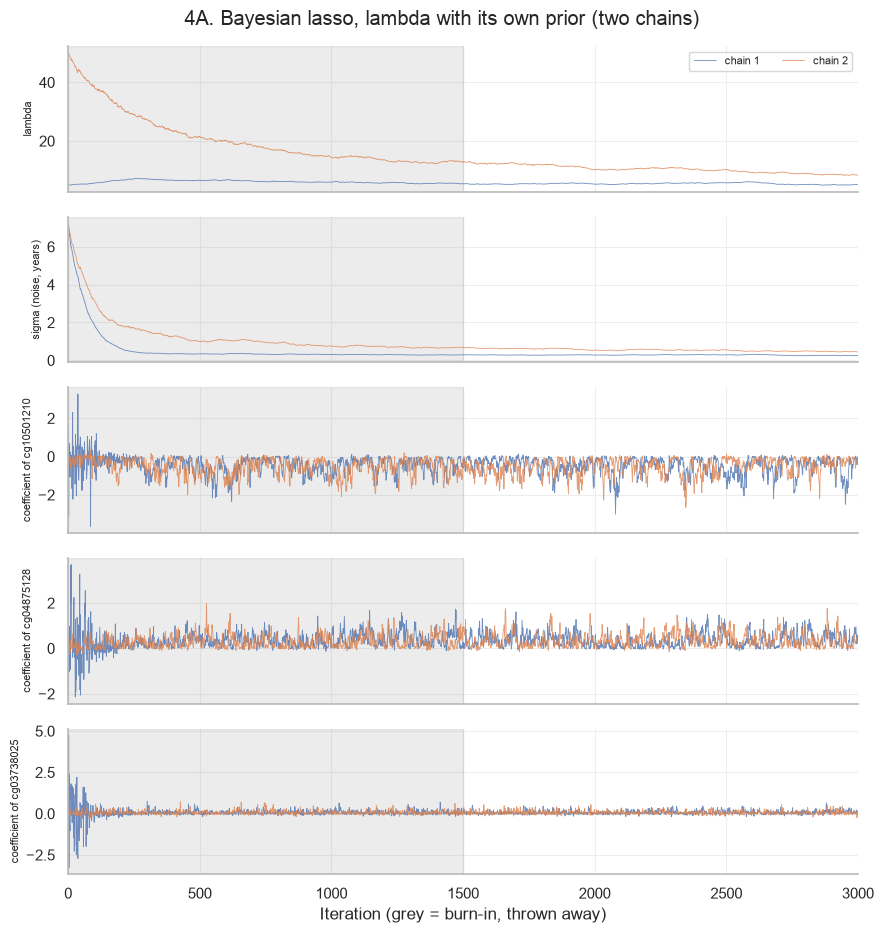

,R-hat
lambda,3.993
"sigma (noise, years)",4.401
coefficient of cg10501210,1.001
coefficient of cg04875128,1.000
coefficient of cg03738025,1.000


In [87]:
trace_plots(traces, BURN_IN, True, "4A. Bayesian lasso, lambda with its own prior (two chains)", "blasso_traces.png")

**What 4A keeps** 

The Bayesian lasso does not set coefficients exactly to zero, as plain lasso does, so there is no automatic list of selected sites. The Bayesian lasso gives a distribution for each coefficient and none of them is exactly zero. To compare, I count the sites where the middle 95% of the draws does not include zero, since for those the model is fairly sure that the effect is not zero and I check how many of them the lasso also kept.

In [72]:
beta_mean = np.concatenate(beta_draws).mean(axis=0)     # posterior mean of every coefficient
lambda_draws = np.sqrt(np.concatenate([t["lam2"][BURN_IN:] for t in traces]))
print(f"lambda (posterior median): {np.median(lambda_draws):.2f}")
count_sites(beta_draws)

lambda (posterior median): 7.18
sites with a 95% credible interval that excludes zero: 0 of 20,000
sites kept by the lasso: 151 | in both: 0


**Results of 4A** 

The two chains do not agree. R-hat is about 4 for both lambda and sigma and the lines are still sloping down at the end. Sigma has been decreased to 0.3 - 0.5 years, far below the real error of about 7 years, which means that the model fits the training data almost perfectly (overfitting). So this version has not converged and I do not use it for the comparison. The three coefficients mix well (R-hat about 1), but lambda and sigma do not. None of the 20,000 sites has an interval that excludes zero.

---
### 4B. Bayesian lasso with lambda fixed

In 4A the data say very little about lambda (20,000 sites and only 524 samples), so lambda and the noise estimate drift slowly and the two chains do not agree. In 4B I fix lambda to the value that matches the lasso from cross-validation (the same penalty on the Bayesian scale: lambda = n x alpha / RMSE of the lasso). This is a practical choice of mine, not a method from the paper. The sampler then only has to find the coefficients and the noise level. The two chains start at different noise levels (3 and 15 years).

In [73]:
N_ITER_B, BURN_B = 1000, 500
LAMBDA = len(y_train) * lasso_alpha / cv_table.loc["Lasso", "RMSE (years)"]   # the lasso penalty on the Bayesian scale (fixed)
print(f"lambda (fixed, matches the lasso): {LAMBDA:.1f}")

path_B = PROC_DIR / f"blasso_fixed_draws_{N_ITER_B}_{BURN_B}_{THIN}_{LAMBDA:.1f}_{Z_train.shape[1]}.npz"
beta_draws_fixed, traces_fixed = run_chains(path_B, N_ITER_B, BURN_B, learn_lambda=False,
                                            lam_starts=[LAMBDA] * N_CHAINS, sigma_starts=[3.0, 15.0])

lambda (fixed, matches the lasso): 44.4
loading saved draws: data/processed/blasso_fixed_draws_1000_500_5_44.4_20000.npz
saved draws of the coefficients: 200 x 20000


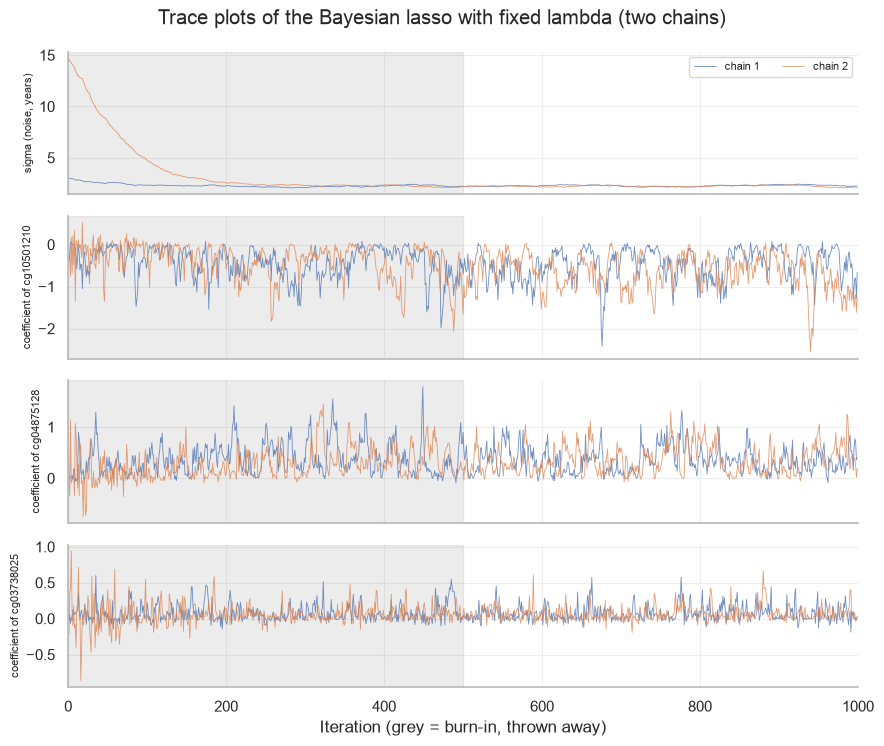

,R-hat
"sigma (noise, years)",1.072
coefficient of cg10501210,1.055
coefficient of cg04875128,0.999
coefficient of cg03738025,0.999


lambda (fixed, matches the lasso): 44.4
sites with a 95% credible interval that excludes zero: 1 of 20,000
sites kept by the lasso: 151 | in both: 1


In [88]:
trace_plots(traces_fixed, BURN_B, False, "Trace plots of the Bayesian lasso with fixed lambda (two chains)", "blasso_traces_fixed_lambda.png")

draws_B = np.concatenate(beta_draws_fixed)       # all saved draws, both chains
beta_mean_fixed = draws_B.mean(axis=0)           # posterior mean of every coefficient (used for the predictions in section 5)
print(f"lambda (fixed, matches the lasso): {LAMBDA:.1f}")
count_sites(beta_draws_fixed)

**Results of 4B** 

The chains agree (the model has converged). The orange chain starts at 15 years and comes down to the same level as the blue one (about 2.3 years) within 250 iterations. R-hat is 1.07 for sigma and between 0.999 and 1.055 for the three coefficients, close to 1. So this version has converged and it is the one I use in section 5.

- Sigma (about 2.3 years) is much smaller than the cross-validated error of the lasso (about 6.7 years). The model fits the training data too closely, so its uncertainty intervals will probably be too narrow. In section 5 I check how often the real age falls inside them.
- Only 1 of the 20,000 sites has a credible interval that excludes zero and it is 1 of the 151 sites of the lasso. This does not mean that there is no signal. Many methylation sites are strongly correlated, so the effect is shared between many of them. The Bayesian lasso spreads it over many sites and no single site stands out, while the lasso picks a few from each group of correlated sites. So the Bayesian lasso is not a good tool for choosing sites here.

---
### 5. Final comparison on the test set

The test set has been kept aside until now and is used **once**: every model is fitted on the training set only and then asked to predict the 132 test samples. Errors are in years. For the Bayesian lasso I use 4B (lambda fixed), the version that converged. It gives many sets of coefficients, one for every saved iteration of the sampler, so for the predictions I use the average of all of them (the posterior mean).

In [75]:
ymean = float(y_train.mean())
ridge_fit = Ridge(alpha=ridge_alpha).fit(Z_train, y_train)
lasso_fit = Lasso(alpha=lasso_alpha, max_iter=5000).fit(Z_train, y_train)

test_pred = {
    "Reference: always predict the mean age": np.full(len(y_test), ymean),
    "Ridge": ridge_fit.predict(Z_test),
    "Lasso": lasso_fit.predict(Z_test),
    "Bayesian lasso (fixed lambda)": ymean + Z_test @ beta_mean_fixed,
}
test_table = pd.DataFrame({name: errors(y_test, pred) for name, pred in test_pred.items()}).T.round(2)
test_table["sites in the model"] = ["-", f"{Z_train.shape[1]:,}", f"{int((lasso_fit.coef_ != 0).sum()):,}", f"{Z_train.shape[1]:,} (shrunk)"]
test_table["cross-validated RMSE (section 3)"] = [cv_table.loc["Reference: always predict the mean age", "RMSE (years)"],
                                                   cv_table.loc["Ridge", "RMSE (years)"], cv_table.loc["Lasso", "RMSE (years)"], "-"]
test_table.to_csv(RES_DIR / "test_errors.csv")
display(test_table)

,RMSE (years),MAE (years),sites in the model,cross-validated RMSE (section 3)
Reference: always predict the mean age,14.98,11.99,-,14.73
Ridge,7.26,5.74,"20,000",7.93
Lasso,6.61,5.58,151,6.71
Bayesian lasso (fixed lambda),7.24,5.75,"20,000 (shrunk)",-


### 5.1 Uncertainty intervals

A single predicted age is not enough, so each method also gets an interval around its prediction.

- **Ridge and Lasso: bootstrap.** scikit-learn has no function that returns prediction intervals, but it has a built-in bootstrap, `BaggingRegressor(bootstrap=True)`. It refits the lasso (with the same penalty) on 200 resampled copies of the training set. The 2.5% and 97.5% quantiles of the 200 predictions give a 95% interval. This interval shows how much the prediction changes when the training data change.
- **Bayesian lasso: posterior.** Every saved draw of the coefficients gives a prediction and the same quantiles give a 95% credible interval. I also make a wider interval that adds the random noise of one person (the sigma of the model), which is what a new observation would look like.

So the bootstrap and the credible interval are about the **model**, and the second Bayesian interval is about a **new person**. The cell also reports the share of observed test ages that fall inside each interval (coverage). 

In [45]:
# Ridge and lasso: bootstrap. Refit the model on 200 resampled copies of the training set (with the same penalty as before)
def bootstrap_interval(model):
    bagging = BaggingRegressor(model, n_estimators=200, bootstrap=True, random_state=SEED, n_jobs=-1)
    bagging.fit(Z_train, y_train)
    preds = np.array([m.predict(Z_test) for m in bagging.estimators_])   # 200 predictions for every test sample
    return np.quantile(preds, [0.025, 0.975], axis=0)                    # 2.5% and 97.5% quantiles = 95% interval


ridge_lo, ridge_hi = bootstrap_interval(Ridge(alpha=ridge_alpha))
lasso_lo, lasso_hi = bootstrap_interval(Lasso(alpha=lasso_alpha, max_iter=5000))

# Bayesian lasso: every saved draw of the coefficients gives one prediction for every test sample
saved_iterations = np.arange(BURN_B, N_ITER_B, THIN)                              # the iterations that were saved
sigma_draws = np.sqrt(np.concatenate([t["sigma2"][saved_iterations] for t in traces_fixed]))   # the noise level in each saved iteration
mu_draws = ymean + draws_B.astype(np.float64) @ Z_test.T
bl_lo, bl_hi = np.quantile(mu_draws, [0.025, 0.975], axis=0)                      # credible interval

# Interval for a new person: add random noise with the model's sigma to every prediction
noise = np.random.default_rng(SEED).standard_normal(mu_draws.shape) * sigma_draws[:, None]
new_draws = mu_draws + noise
bl_plo, bl_phi = np.quantile(new_draws, [0.025, 0.975], axis=0)


# Coverage: the share of observed test ages that fall inside the interval
yt = y_test.values
def coverage(lo, hi):
    return float(np.mean((yt >= lo) & (yt <= hi)))


intervals = {
    "Ridge, bootstrap interval": (ridge_lo, ridge_hi),
    "Lasso, bootstrap interval": (lasso_lo, lasso_hi),
    "Bayesian lasso, credible interval": (bl_lo, bl_hi),
    "Bayesian lasso, interval for a new observation": (bl_plo, bl_phi),
}
interval_table = pd.DataFrame({
    name: {"share of test ages inside the 95% interval": coverage(lo, hi), "mean width (years)": float(np.mean(hi - lo))}
    for name, (lo, hi) in intervals.items()
}).T.round(2)
interval_table.to_csv(RES_DIR / "interval_coverage.csv")
display(interval_table)
print(f"noise level of the Bayesian lasso (posterior median sigma): {np.median(sigma_draws):.1f} years | test RMSE of the Bayesian lasso: {test_table.loc['Bayesian lasso (fixed lambda)', 'RMSE (years)']}")

,share of test ages inside the 95% interval,mean width (years)
"Ridge, bootstrap interval",0.32,5.30
"Lasso, bootstrap interval",0.44,8.30
"Bayesian lasso, credible interval",0.96,32.95
"Bayesian lasso, interval for a new observation",0.98,34.14


noise level of the Bayesian lasso (posterior median sigma): 2.3 years | test RMSE of the Bayesian lasso: 7.24


### 5.2 Predicted versus observed age

Each point is a test sample. The x-axis is the **predicted** age with its 95% interval as a horizontal bar and the y-axis is the **observed** age. A perfect model would put all points on the dotted diagonal. Ridge has no interval, so it only has points. For the Bayesian lasso the dark bar is the credible interval. The interval for a new person is almost the same width, so it is not drawn.

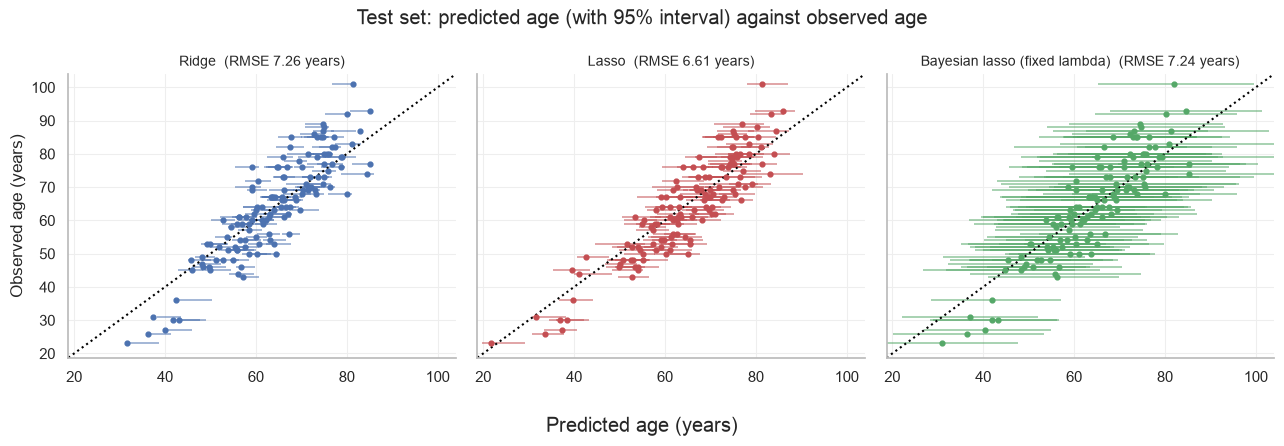

In [89]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), sharex=True, sharey=True)

# the same axis range in all three plots
all_values = np.concatenate([yt, *test_pred.values()])
lims = [all_values.min() - 3, all_values.max() + 3]


def panel(ax, pred, title, color, bars=()):
    # draw the interval bars (if any), then the points, then the diagonal
    for lo, hi, width, alpha in bars:
        ax.hlines(yt, lo, hi, color=color, lw=width, alpha=alpha)
    ax.scatter(pred, yt, s=12, color=color, zorder=3)
    ax.plot(lims, lims, ls=":", color="black")
    ax.set_title(f"{title}  (RMSE {test_table.loc[title, 'RMSE (years)']} years)", fontsize=10)

    ax.grid(True, color="#eeeeee", linewidth=0.8)   # faint grid
    ax.set_axisbelow(True)
    sns.despine(ax=ax)
    ax.spines["left"].set_color("#bbbbbb")
    ax.spines["bottom"].set_color("#bbbbbb")


panel(axes[0], test_pred["Ridge"], "Ridge", "#4C72B0", bars=[(ridge_lo, ridge_hi, 1.2, 0.6)])
panel(axes[1], test_pred["Lasso"], "Lasso", "#C44E52", bars=[(lasso_lo, lasso_hi, 1.2, 0.6)])
panel(axes[2], test_pred["Bayesian lasso (fixed lambda)"], "Bayesian lasso (fixed lambda)", "#55A868",
      bars=[(bl_lo, bl_hi, 1.2, 0.6)])
axes[0].set_ylabel("Observed age (years)")
axes[0].set_xlim(lims)
axes[0].set_ylim(lims)
fig.supxlabel("Predicted age (years)")
fig.suptitle("Test set: predicted age (with 95% interval) against observed age")
fig.tight_layout()
fig.savefig(FIG_DIR / "test_predictions.png", dpi=200)
plt.show()

**What the intervals show**

- **Ridge and lasso bootstrap intervals:** only 32% (ridge) and 44% (lasso) of the test ages fall inside, and the mean widths are 5.3 years (ridge) and 8.3 years (lasso). This is expected, because the bootstrap shows how much the fitted model changes with the training data. It does not include the differences between people, so it is not a prediction interval.
- **Bayesian lasso intervals:** 96% to 98% of the test ages fall inside, but they are about 33 years wide. They are so wide because the individual draws disagree strongly on new samples, even though their average predicts well. The width does not come from the noise estimate, which is only 2.3 years (the real error is about 7 years). So these intervals are safe but not very informative.

### 5.3 What the results say

Results on the test set (132 samples, error in years):

| Model | RMSE | MAE | Sites used |
|---|---|---|---|
| Always predict the mean | 14.98 | 11.99 | - |
| Ridge | 7.26 | 5.74 | 20,000 |
| Lasso | 6.61 | 5.58 | 151 |
| Bayesian lasso (fixed lambda) | 7.24 | 5.75 | 20,000 (shrunk) |

- All three models predict age much better than the reference. Cross-validation (section 3) and the test set give the same order.
- Answer to the question: keeping only a small set of sites (lasso) does not hurt compared with shrinking all of them (ridge). It is slightly better by RMSE and about equal by MAE, with 151 sites instead of 20,000. The difference is small and comes from one split of 132 samples, so it should not be over-interpreted.
- The Bayesian lasso predicts as well as ridge. Its main addition is uncertainty, but its 95% intervals are very wide (about 33 years), while the lasso bootstrap intervals are narrow (about 8 years) and cover only 44% of the observed ages, because they show the uncertainty of the model and not the differences between people.
- All models predict the oldest samples too young and the youngest too old.

---
### 6. Justification of the graphs and limitations

### Why these graphs
- **Histograms** (age, average methylation): they show how one number is spread out. So, we can see the age range the models learn from and check that the methylation values look reasonable.
- **Scatter plots of the sites most correlated with age:** both variables are continuous, so points show the shape of the relation (here roughly linear) and how much the samples scatter around it.
- **Line plots of cross-validated error against the penalty:** the penalty is a continuous scale, so a line shows how the error changes and where it is lowest. The band shows the spread between folds and the dotted line is the reference that always predicts the mean.
- **Trace plots:** they show, iteration by iteration, if the chains of the Gibbs sampler have settled and agree. R-hat gives the same information as one number.
- **Predicted against observed age, with the interval on the x-axis:** a perfect model would be on the diagonal, so distance from the diagonal is the error and the horizontal bar shows how unsure each prediction is. The same axes in all three plots make the models easy to compare.

### Limitations
- Linear model: Ridge and lasso assume that age changes linearly with methylation. Non-linear patterns are not captured.
- One dataset: It is whole blood from adults only (19 to 101 years) in one study. The results may not hold for other tissues, children or other populations.
- Variance filter and scaling: The 20,000 most variable sites were chosen and the sites were standardised, using all samples, including the test samples. Age was not used, but the test samples were not fully untouched. The filter may also have removed sites that vary little but are informative about age.
- Penalty chosen on the same folds that estimate the error: The cross-validated errors are therefore slightly optimistic. The test set is the honest estimate.
- One split: All conclusions come from one train/test split of 132 test samples, so small differences between the models (for example lasso against ridge) may not be reliable.
- Bayesian lasso: The version where lambda has its own prior (4A) did not converge in 3,000 iterations. The version used for the comparison (4B) has lambda fixed from the cross-validated lasso, so the penalty is not learned by the Bayesian model and its noise estimate (about 2 years) is much smaller than the real error (about 7 years). I also checked convergence for only three coefficients, not all 20,000. Park and Casella (2008) also suggest estimating lambda with empirical Bayes, which I did not try.
- Intervals: The lasso bootstrap uses a fixed penalty and shows the uncertainty of the model, not of a new person. The Bayesian intervals are very wide.

---
### 7. Relation to FAIR data principles and license

**Findable**
- The data has a public identifier, the GEO accession number GSE40279, with a description, sample information and a related publication (Hannum et al. 2013. Genome-wide methylation profiles reveal quantitative views of human aging rates. Molecular cell, 49(2), 359–367. https://doi.org/10.1016/j.molcel.2012.10.016).
- The code is in a GitHub repository with a README that states the motivation of the project, the data and how to run it. A Zenodo archive gives it a DOI. GitHub repository: https://github.com/ekazasi/methylation-age-prediction.git, Zenodo DOI: [![DOI](https://zenodo.org/badge/1424738242.svg)](https://doi.org/10.5281/zenodo.23458258).
- This project is findable by both humans and computers. By adding topics in the GitHub page, related to the project, it turns up in GitHub's topic browsing and search.

**Accessible**
- Anyone can download the data from GEO over HTTPS without an account. The notebook downloads it by accession, so the raw data is not copied into the repository because it is large.
- The notebook itself and the functions in it, are plain python that is easily installed and free.
- The GitHub repository and Zenodo DOI are public so everyone can have access.

**Interoperable**
- The data has standard open formats (tab-separated text, compressed). Sites are named with the standard Illumina CpG identifiers (cg numbers), which can be linked to other resources. 
- Standard Jupyter notebook in Python with common libraries (scikit-learn, pandas, numpy) and results that are saved as CSV and PNG files, that are widely used. 

**Reusable**
- The data are open-source, so it can be used again.
- The *yaml* file creates the environment with the package versions used in the initial run, so the whole workflow can be run and produce the same results.
- A fixed random seed is used.
- The README file and the limitations section explain what the results can and cannot be used for.
- In general, the structure of the notebook presents a reproducible pipeline.